# Capstone — End-to-End AI Foundation Pipeline

**Overview:** raw data → Pandas/NumPy preprocessing → leakage-safe split → scaling →
PyTorch `Dataset`/`DataLoader` → `nn.Module` model → training loop with checkpointing →
evaluation (precision/recall/F1/ROC-AUC) → inference. Every stage reuses something already
built and validated earlier in this curriculum — see the README for the full map.

**Required libraries:** `numpy`, `pandas`, `scikit-learn`, `torch`, `matplotlib`.

**Dataset:** `sklearn.datasets.load_breast_cancer` — 569 samples, 30 features, binary
classification, built into scikit-learn (no download).

## 0. Environment

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              roc_auc_score, confusion_matrix)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
print("torch:", torch.__version__)


torch: 2.14.1


## 1. Raw data → Pandas (Day 1: `01_python`, `02_numpy`, `03_data_libraries`)

In [2]:
raw = load_breast_cancer()
df = pd.DataFrame(raw.data, columns=raw.feature_names)
df["target"] = raw.target   # 0 = malignant, 1 = benign

print("shape:", df.shape)
print("\nmissing values:", df.isna().sum().sum(), "(should be 0 -- this dataset is clean)")
print("\nclass balance:\n", df["target"].value_counts(normalize=True))
df.head()


shape: (569, 31)

missing values: 0 (should be 0 -- this dataset is clean)

class balance:
 target
1    0.627417
0    0.372583
Name: proportion, dtype: float64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 2. Train / validation / test split, leakage-safe (Day 1: `04_datasets`, Day 2: `12_ml_evaluation`)

⚠️ **Common Mistake:** scaling before splitting -- the exact leakage pattern called out
repeatedly across Day 1 and Day 2. We split FIRST, then fit the scaler on the training split
ONLY.

In [3]:
X = df.drop(columns=["target"]).values.astype(np.float32)
y = df["target"].values.astype(np.int64)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp)

print(f"train: {len(X_train)}, val: {len(X_val)}, test: {len(X_test)}")
for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name} class balance: {np.bincount(labels) / len(labels)}")


train: 398, val: 85, test: 86
train class balance: [0.3718593 0.6281407]
val class balance: [0.37647059 0.62352941]
test class balance: [0.37209302 0.62790698]


## 3. Feature scaling (Day 2: `13_feature_engineering`) -- fit on TRAIN ONLY

In [4]:
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("train mean after scaling (should be ~0):", X_train_scaled.mean(axis=0)[:3].round(3))
print("train std after scaling (should be ~1): ", X_train_scaled.std(axis=0)[:3].round(3))
assert np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-6)


train mean after scaling (should be ~0): [0. 0. 0.]
train std after scaling (should be ~1):  [1. 1. 1.]


## 4. PyTorch `Dataset` and `DataLoader` (Day 3: `21_pytorch_data`)

In [5]:
from torch.utils.data import Dataset, DataLoader

class TabularDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(TabularDataset(X_train_scaled, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(TabularDataset(X_val_scaled, y_val), batch_size=32, shuffle=False)
test_loader = DataLoader(TabularDataset(X_test_scaled, y_test), batch_size=32, shuffle=False)

print(f"train batches: {len(train_loader)}, val batches: {len(val_loader)}, test batches: {len(test_loader)}")


train batches: 13, val batches: 3, test batches: 3


## 5. Model: an `nn.Module` MLP (Day 3: `20_pytorch_models`)

In [6]:
class TumorClassifier(nn.Module):
    def __init__(self, in_features, hidden_units=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden_units),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden_units, hidden_units // 2),
            nn.ReLU(),
            nn.Linear(hidden_units // 2, 2),   # 2 classes: malignant / benign
        )

    def forward(self, x):
        return self.net(x)

model = TumorClassifier(in_features=X.shape[1])
print(model)
print("\ntotal parameters:", sum(p.numel() for p in model.parameters()))


TumorClassifier(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=2, bias=True)
  )
)

total parameters: 1554


## 6. Training loop with validation and checkpointing (Day 3: `22_pytorch_training`)

early stopping at epoch 50 (best val_loss=0.0508)

final train_loss=0.0285, val_loss=0.0663


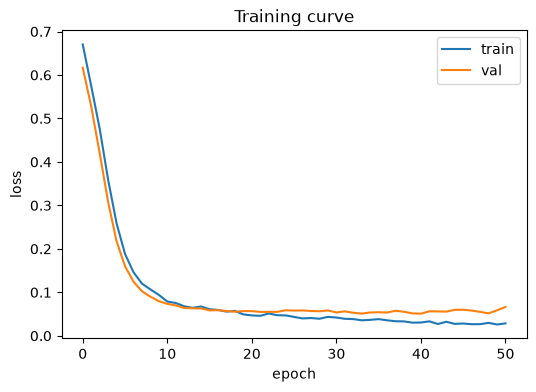

In [7]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss = 0.0
    for X_batch, y_batch in loader:
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(X_batch)
    return total_loss / len(loader.dataset)

@torch.no_grad()
def evaluate_loss(model, loader, loss_fn):
    model.eval()
    total_loss = 0.0
    for X_batch, y_batch in loader:
        logits = model(X_batch)
        loss = loss_fn(logits, y_batch)
        total_loss += loss.item() * len(X_batch)
    return total_loss / len(loader.dataset)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
loss_fn = nn.CrossEntropyLoss()

CHECKPOINT_PATH = "best_tumor_classifier.pt"
best_val_loss = float("inf")
patience, epochs_since_improvement = 10, 0
train_losses, val_losses = [], []

for epoch in range(100):
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
    val_loss = evaluate_loss(model, val_loader, loss_fn)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        epochs_since_improvement = 0
        torch.save(model.state_dict(), CHECKPOINT_PATH)
    else:
        epochs_since_improvement += 1
        if epochs_since_improvement >= patience:
            print(f"early stopping at epoch {epoch} (best val_loss={best_val_loss:.4f})")
            break

print(f"\nfinal train_loss={train_losses[-1]:.4f}, val_loss={val_losses[-1]:.4f}")
assert val_losses[-1] < val_losses[0]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(train_losses, label="train"); ax.plot(val_losses, label="val")
ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.set_title("Training curve"); ax.legend()
plt.show()


## 7. Evaluation: precision/recall/F1/ROC-AUC, not just accuracy (Day 2: `12_ml_evaluation`)

⚠️ **Common Mistake:** reporting only accuracy. With a ~63%/37% class balance here it isn't
extreme, but the discipline of checking precision/recall/F1/ROC-AUC still matters -- and
matters far more on a more imbalanced real dataset.

In [8]:
best_model = TumorClassifier(in_features=X.shape[1])
best_model.load_state_dict(torch.load(CHECKPOINT_PATH, weights_only=True))
best_model.eval()

all_preds, all_probs, all_true = [], [], []
with torch.no_grad():
    for X_batch, y_batch in test_loader:
        logits = best_model(X_batch)
        probs = torch.softmax(logits, dim=1)[:, 1]   # probability of class "1" (benign)
        preds = logits.argmax(dim=1)
        all_preds.append(preds)
        all_probs.append(probs)
        all_true.append(y_batch)

all_preds = torch.cat(all_preds).numpy()
all_probs = torch.cat(all_probs).numpy()
all_true = torch.cat(all_true).numpy()

acc = accuracy_score(all_true, all_preds)
precision = precision_score(all_true, all_preds)
recall = recall_score(all_true, all_preds)
f1 = f1_score(all_true, all_preds)
roc_auc = roc_auc_score(all_true, all_probs)

print(f"Test accuracy:  {acc:.3f}")
print(f"Test precision: {precision:.3f}")
print(f"Test recall:    {recall:.3f}")
print(f"Test F1:        {f1:.3f}")
print(f"Test ROC-AUC:   {roc_auc:.3f}")
print("\nconfusion matrix:\n", confusion_matrix(all_true, all_preds))

assert acc > 0.85   # this dataset is quite learnable; a reasonable MLP should do well
assert roc_auc > 0.9


Test accuracy:  0.953
Test precision: 0.963
Test recall:    0.963
Test F1:        0.963
Test ROC-AUC:   0.993

confusion matrix:
 [[30  2]
 [ 2 52]]


## 8. Inference on new (held-out) samples (Day 3: `.eval()` + `torch.no_grad()`)

💡 **Key Idea:** inference is nothing more than a forward pass through the already-trained,
now-fixed model -- the exact training-vs-inference distinction from Day 2's
`06_ml_fundamentals`, now concretely demonstrated.

In [9]:
sample_indices = [0, 1, 2, 3, 4]
sample_X = torch.from_numpy(X_test_scaled[sample_indices])
sample_true = y_test[sample_indices]

with torch.no_grad():
    sample_logits = best_model(sample_X)
    sample_probs = torch.softmax(sample_logits, dim=1)
    sample_preds = sample_logits.argmax(dim=1)

label_names = {0: "malignant", 1: "benign"}
for i, idx in enumerate(sample_indices):
    pred_label = label_names[sample_preds[i].item()]
    true_label = label_names[sample_true[i]]
    confidence = sample_probs[i, sample_preds[i]].item()
    match = "correct" if pred_label == true_label else "WRONG"
    print(f"sample {idx}: predicted={pred_label} (confidence={confidence:.3f}), true={true_label}  [{match}]")

import os
os.remove(CHECKPOINT_PATH)   # cleanup


sample 0: predicted=benign (confidence=0.996), true=benign  [correct]
sample 1: predicted=malignant (confidence=1.000), true=malignant  [correct]
sample 2: predicted=malignant (confidence=1.000), true=malignant  [correct]
sample 3: predicted=malignant (confidence=1.000), true=malignant  [correct]
sample 4: predicted=benign (confidence=0.699), true=malignant  [WRONG]


## 9. Summary

✅ This notebook ran the complete pipeline this curriculum has built across all three days:
Pandas/NumPy preprocessing, a leakage-safe split, train-only scaling, a PyTorch
`Dataset`/`DataLoader`, an `nn.Module` model, a training loop with checkpointing and early
stopping, proper multi-metric evaluation, and inference on new samples. Every individual piece
was already validated in its own topic — this is the proof they compose correctly into one
working system.

**This closes the AI/ML Engineer Fundamentals curriculum.** Continue to this workspace's
`llm-fine-tuning/` curriculum for Transformers, LLMs, RAG, fine-tuning, and inference
engineering — all built on exactly the foundations covered here.